In [1]:
import os, sys
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
import ROOT as rt
import fnmatch

## user define
sys.path.append('.')
sys.path.append('./Utils')
from Plotter import HistStack

from beeps import *

Welcome to JupyROOT 6.26/08


# Set config

In [2]:
# ERA="ee17"
# ERA="ee16pre"
# # ERA="mm18"
# ERA="em18"
# # DATE = '20230129_17_eleffmva'
# DATE = '20230301_18'
# # DATE = '20230130_18_dyhighworctight'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/20230130_18_dyhighworctight/mm/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230301_18/em/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
INPUTDIR = sys.argv[3]

DUMP_PKL = True
DRAW_SR = True
RUN_SIDEBAND_MET = True
RUN_SIDEBAND_MASS = True
RUN_SIDEBAND_PT = True
DUMP_SIDEBAND_MET_PKL = True
DUMP_SIDEBAND_MASS_PKL = True
DUMP_SIDEBAND_PT_PKL = True
RUN_BTAG = False
EXPORT_VARIABLE = False

# # for dev
# ERA="ee18"
# DATE = '20230419_18'
# INPUTDIR = "/eos/user/h/hkwon/Run2/"+DATE+"/ee/"


# Get input

In [3]:
lumi_all={
    "ee16pre":19520,
    "ee16post":16810,
    "ee17":41480,
    "ee18":59830,
    "mm16pre":19520,
    "mm16post":16810,
    "mm17":41480,
    "mm18":59830,    
#     "mm18":14000,    
    "em16pre":19520,
    "em16post":16810,
    "em17":41480,
    "em18":59830     
}

data_evts = {
    "ee16pre":652566543,
    "ee16post":287977115,
    "ee17":460041183,
    "ee18":1326465857,
    "mm16pre":458655573,
    "mm16post":327037313,
    "mm17":739073837,
    "mm18":944842550,    
    "em16pre":1111222116,
    "em16post":287977115,
    "em17":1199115020,
    "em18":2271308407     
}

lumi=lumi_all[ERA]
print(ERA, lumi)

channel = ERA.replace("16pre", "")
channel = channel.replace("16post", "")
channel = channel.replace("17", "")
channel = channel.replace("18", "")

def get_df(root_file_name, unneccesary_columns):
    f = uproot.open(root_file_name)
    df = uproot.open(root_file_name)["Events_"+channel].arrays(library="pd")
    df_met_u = uproot.open(root_file_name)["Events_"+channel+"_met_u"].arrays(library="pd")
    df_met_d = uproot.open(root_file_name)["Events_"+channel+"_met_d"].arrays(library="pd")    
#     df_scale_u = uproot.open(root_file_name)["Events_"+channel+"_scale_u"].arrays(library="pd")
#     df_scale_d = uproot.open(root_file_name)["Events_"+channel+"_scale_d"].arrays(library="pd")
    info = uproot.open(root_file_name)["Info_"+channel].arrays(library="pd")
#     return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1), df_scale_u.drop(unneccesary_columns, axis=1), df_scale_d.drop(unneccesary_columns, axis=1)
    return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1)

unneccesary_columns = []
dic_input = {
    "ee16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/ee/",
    "mm16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/mm/",
    "em16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/em/",
    "ee16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/ee/",
    "mm16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/mm/",
    "em16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/em/",
    "ee17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/ee/",
    "mm17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/mm/",
    "em17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/em/",
    "ee18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/ee/",
    "mm18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/mm/",    
    "em18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/em/"        
#     "em18": "/eos/user/h/hkwon/Run2/20221120_18/em/"        
}
# input_dir = dic_input[ERA]
input_dir = INPUTDIR
f = []
for (dirpath, dirnames, filenames) in os.walk(input_dir):
    f.extend(filenames)
    break

dic_tup={}
for file in tqdm(f):
    # file naming: flatNtuple_Preselect_WZ1.root, flatNtuple_Preselect_Zp-3700_CH-1345.root
    if not "flatNtuple" in file:
        continue
#     if channel=="mm" and (fnmatch.fnmatch(file, '*E*Run*') or fnmatch.fnmatch(file, '*M*RunB*') or fnmatch.fnmatch(file, '*M*RunC*') or fnmatch.fnmatch(file, '*M*RunD*')): #temp
    if channel=="mm" and fnmatch.fnmatch(file, '*E*Run*'): #temp
        continue
    if channel=="ee" and fnmatch.fnmatch(file, '*M*Run*'):
        continue
#     if channel=="em" and fnmatch.fnmatch(file, '*E*Run*'):
#         continue  

    if "Zp" in file:
        sample=file.split('_')[2]+"_"+file.split('_')[3]
    else:
        sample=file.split('_')[2]
    sample=sample.rstrip('.root')
    try:
        print(sample)
        dic_tup[sample]=get_df(input_dir+file, unneccesary_columns)   
    except:
        print(sample)
        beep()        
        if "Run" in sample: # check file corrupt
            raise    
# dic_tup

ee18 59830


  0%|          | 0/264 [00:00<?, ?it/s]

DY0


  0%|          | 1/264 [00:00<03:05,  1.42it/s]

DY1


...

 99%|█████████▉| 262/264 [02:42<00:01,  1.45it/s]

Zp-4100_CH-595


100%|█████████▉| 263/264 [02:43<00:00,  1.47it/s]

Zp-4100_CH-845


100%|██████████| 264/264 [02:44<00:00,  1.61it/s]


In [4]:
beep_ok()

In [5]:
# for key in dic_tup:
#     print(key)

In [6]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 10.48, 'WZ': 5.052, 'ZZ': 0.6008, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300_CH-1595': 0.000729, 'Zp-3700_CH-345': 0.00031, 'Zp-3700_CH-595': 0.00031, 'Zp-3700_CH-845': 0.00031, 'Zp-3700_CH-1095': 0.00031, 'Zp-3700_CH

In [7]:
Data_concat, TT_concat, TTSemi_concat, TTZ_concat, DY_concat, top_concat, antitop_concat, WW_concat, WZ_concat, ZZ_concat = ([] for i in range(10))
Data_concat_met_u, TT_concat_met_u, TTSemi_concat_met_u, TTZ_concat_met_u, DY_concat_met_u, top_concat_met_u, antitop_concat_met_u, WW_concat_met_u, WZ_concat_met_u, ZZ_concat_met_u = ([] for i in range(10))
Data_concat_met_d, TT_concat_met_d, TTSemi_concat_met_d, TTZ_concat_met_d, DY_concat_met_d, top_concat_met_d, antitop_concat_met_d, WW_concat_met_d, WZ_concat_met_d, ZZ_concat_met_d = ([] for i in range(10))
Data_concat_scale_u, TT_concat_scale_u, TTSemi_concat_scale_u, TTZ_concat_scale_u, DY_concat_scale_u, top_concat_scale_u, antitop_concat_scale_u, WW_concat_scale_u, WZ_concat_scale_u, ZZ_concat_scale_u = ([] for i in range(10))
Data_concat_scale_d, TT_concat_scale_d, TTSemi_concat_scale_d, TTZ_concat_scale_d, DY_concat_scale_d, top_concat_scale_d, antitop_concat_scale_d, WW_concat_scale_d, WZ_concat_scale_d, ZZ_concat_scale_d = ([] for i in range(10))

Data_nevts, TT_nevts, TTSemi_nevts, TTZ_nevts, DY_nevts, top_nevts, antitop_nevts, WW_nevts, WZ_nevts, ZZ_nevts = ([] for i in range(10))

merged_dic_df={}
for key in dic_tup:
    if fnmatch.fnmatch(key, 'DY?') or fnmatch.fnmatch(key, 'DY??'):
        print(key)
        DY_concat.append(dic_tup[key][1])
        DY_concat_met_u.append(dic_tup[key][2])
        DY_concat_met_d.append(dic_tup[key][3])        
#         DY_concat_scale_u.append(dic_tup[key][4])
#         DY_concat_scale_d.append(dic_tup[key][5])
        DY_nevts.append(dic_tup[key][0])
        print(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TT?') or fnmatch.fnmatch(key, 'TT??'):
        TT_concat.append(dic_tup[key][1])
        TT_concat_met_u.append(dic_tup[key][2])
        TT_concat_met_d.append(dic_tup[key][3])
#         TT_concat_scale_u.append(dic_tup[key][4])
#         TT_concat_scale_d.append(dic_tup[key][5])
        TT_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTSemi*'):
        TTSemi_concat.append(dic_tup[key][1])
        TTSemi_concat_met_u.append(dic_tup[key][2])
        TTSemi_concat_met_d.append(dic_tup[key][3])
#         TTSemi_concat_scale_u.append(dic_tup[key][4])
#         TTSemi_concat_scale_d.append(dic_tup[key][5])
        TTSemi_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTZ*'):
        TTZ_concat.append(dic_tup[key][1])
        TTZ_concat_met_u.append(dic_tup[key][2])
        TTZ_concat_met_d.append(dic_tup[key][3])
#         TTZ_concat_scale_u.append(dic_tup[key][4])
#         TTZ_concat_scale_d.append(dic_tup[key][5])
        TTZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TW?'):
        top_concat.append(dic_tup[key][1])
        top_concat_met_u.append(dic_tup[key][2])
        top_concat_met_d.append(dic_tup[key][3])
#         top_concat_scale_u.append(dic_tup[key][4])
#         top_concat_scale_d.append(dic_tup[key][5])
        top_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'TWa?'):
        antitop_concat.append(dic_tup[key][1])
        antitop_concat_met_u.append(dic_tup[key][2])
        antitop_concat_met_d.append(dic_tup[key][3])
#         antitop_concat_scale_u.append(dic_tup[key][4])
#         antitop_concat_scale_d.append(dic_tup[key][5])
        antitop_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'WW*'):
        WW_concat.append(dic_tup[key][1])
        WW_concat_met_u.append(dic_tup[key][2])
        WW_concat_met_d.append(dic_tup[key][3])
#         WW_concat_scale_u.append(dic_tup[key][4])
#         WW_concat_scale_d.append(dic_tup[key][5])
        WW_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'WZ*'):
        WZ_concat.append(dic_tup[key][1])
        WZ_concat_met_u.append(dic_tup[key][2])
        WZ_concat_met_d.append(dic_tup[key][3])
#         WZ_concat_scale_u.append(dic_tup[key][4])
#         WZ_concat_scale_d.append(dic_tup[key][5])
        WZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'ZZ*'):
        ZZ_concat.append(dic_tup[key][1])
        ZZ_concat_met_u.append(dic_tup[key][2])
        ZZ_concat_met_d.append(dic_tup[key][3])
#         ZZ_concat_scale_u.append(dic_tup[key][4])
#         ZZ_concat_scale_d.append(dic_tup[key][5])
        ZZ_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, '*Run*'):
        Data_concat.append(dic_tup[key][1])
        Data_concat_met_u.append(dic_tup[key][2])
        Data_concat_met_d.append(dic_tup[key][3])
#         Data_concat_scale_u.append(dic_tup[key][4])
#         Data_concat_scale_d.append(dic_tup[key][5])
        Data_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'Zp*'): 
        merged_dic_df[key]=dic_tup[key]
    if fnmatch.fnmatch(key, 'DY*To*'): 
        merged_dic_df[key]=dic_tup[key]
        print("high", key)

DY0
3081301
DY1
5137820
DY10
7717518
high DY1000To15000
DY11
10415848
DY12
6149058
DY13
5039444
DY14
7189686
DY15
9197157
high DY1500To20000
DY16
5888770
DY17
3749225
DY18
5011966
DY19
4754430
DY2
6466029
DY20
2963693
high DY2000To30000
DY3
6850646
DY4
9022257
DY5
6110199
high DY500To7000
DY6
6402318
DY7
5567140
high DY700To8000
DY8
5517922
high DY800To10000
DY9
9332911


In [8]:
# free memory 
dic_tup.clear()

In [9]:
totalinput = """
######################################################
####   Total input number of events (sumweight)   ####
######################################################
"""

print(totalinput)
if TT_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d)
    tmp = "TT: "+str(sum(TT_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TTSemi_concat:
#     merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d), pd.concat(TTSemi_concat_scale_u), pd.concat(TTSemi_concat_scale_d)
    merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d)
    tmp = "TTSemi: "+str(sum(TTSemi_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTZ_concat:
#     merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d), pd.concat(TTZ_concat_scale_u), pd.concat(TTZ_concat_scale_d)
    merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d)
    tmp = "TTZ: "+str(sum(TTZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if DY_concat:
#     merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d), pd.concat(DY_concat_scale_u), pd.concat(DY_concat_scale_d)
    merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d)
    tmp = "DY: "+str(sum(DY_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if top_concat:
    df=pd.concat(top_concat)
#     merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d), pd.concat(top_concat_scale_u), pd.concat(top_concat_scale_d)
    merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d)
    tmp = "top: "+str(sum(top_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if antitop_concat:
    df=pd.concat(antitop_concat)
#     merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d), pd.concat(antitop_concat_scale_u), pd.concat(antitop_concat_scale_d)
    merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d)
    tmp = "antitop: "+str(sum(antitop_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if ZZ_concat:
    df=pd.concat(ZZ_concat)
#     merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d), pd.concat(ZZ_concat_scale_u), pd.concat(ZZ_concat_scale_d)
    merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d)
    tmp = "ZZ: "+str(sum(ZZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WZ_concat:
    df=pd.concat(WZ_concat)
#     merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d), pd.concat(WZ_concat_scale_u), pd.concat(WZ_concat_scale_d)
    merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d)
    tmp = "WZ: "+str(sum(WZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WW_concat:
    df=pd.concat(WW_concat)
#     merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d), pd.concat(WW_concat_scale_u), pd.concat(WW_concat_scale_d)
    merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d)
    tmp = "WW: "+str(sum(WW_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if Data_concat:
#     merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d), pd.concat(Data_concat_scale_u), pd.concat(Data_concat_scale_d)
    merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d)
    tmp = "Data: "+str(sum(Data_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
# merged_dic_df["Zp-2500"]=dic_tup["Zp-2500"][0], dic_tup["Zp-2500"][1] 



######################################################
####   Total input number of events (sumweight)   ####
######################################################

TT: 153500682
TTSemi: 472557630
TTZ: 9651834
DY: 131565338
top: 7955614
antitop: 7748690
ZZ: 56766176
WZ: 24303029
WW: 9956710
Data: 1326465857


In [10]:
os.system("mkdir -p "+DATE+"/Presel/"+ERA)
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'w') as f:
    f.write(totalinput)

In [11]:
try:
   if data_evts[ERA]!=sum(Data_nevts):
       raise ValueError('Data events missing!')
except (ValueError, IndexError):
   beep()
   print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts)) 
   raise

expected: 1326465848 , while:  1326465857


ValueError: Data events missing!

In [12]:
# # temp!!
for key in merged_dic_df:
    df = merged_dic_df[key][1]
    df_met_u = merged_dic_df[key][2]
    df_met_d = merged_dic_df[key][3]    
#     df_scale_u = merged_dic_df[key][4]
#     df_scale_d = merged_dic_df[key][5]
#     print(df[df.isin([np.inf, -np.inf]).any(1)])
    if df.isnull().values.any():
        print("Warning, nan in",key)
        i = df[df.isin([np.nan, np.inf, -np.inf]).any(1)].index
        print(i)
        df_new = df.drop(i)
        df_met_u_new = df_met_u.drop(i)
        df_met_d_new = df_met_d.drop(i)
#         print(df_new.isnull().values.any())
        #workaround for tuple assignment
#         merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new, df_scale_u, df_scale_d
        merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new
        


In [13]:
sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre', 'trigSF_pre']
eventweights = """
####################################################
####       event weights (normalization)        ####
####################################################
"""

def get_dic_with_weight(merged_dic_df):
    dic_df={}
    dic_df_met_u={}
    dic_df_met_d={}
    dic_df_scale_u={}
    dic_df_scale_d={}
    for key, vs in merged_dic_df.items():
        print(key)
        if "16pre" in ERA and key=="Zp-2500_CH-595": # signal sample missing
            continue    
        if "Data" in key:
            norm=1
        else:
            if fnmatch.fnmatch(key, '*DY*To*'):
                key = key[:len(key)-1]
            norm=lumi*dic_xsec[key]/vs[0]
        print(key, ":", norm)
        global eventweights
        eventweights+=key+":"+str(norm)+"\n"
#         print(eventweights)
        dic_df[key]=vs[1]
        dic_df_met_u[key] = vs[2]
        dic_df_met_d[key]=vs[3]
#         dic_df_scale_u[key] = vs[4]
#         dic_df_scale_d[key]=vs[5]
        dic_df[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_u[key]["weightmetUp"] = vs[1]["genweight_pre"]*norm
        dic_df_met_d[key]["weightmetDown"] = vs[1]["genweight_pre"]*norm
#         dic_df_scale_u[key]["weightscaleUp"] = vs[4]["totweight"].copy(deep=True)
#         dic_df_scale_d[key]["weightscaleDown"] =vs[5]["totweight"].copy(deep=True)
        dic_df[key]["wopu"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wol1"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["woeff"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wotop"] = vs[1]["genweight_pre"]*norm       
        dic_df[key]["wobsf"] = vs[1]["genweight_pre"]*norm       
      
        for s in sys:
            if s=="genweight_pre":
                continue
            dic_df[key]["weight"] *= vs[1][s]
            dic_df_met_u[key]["weightmetUp"] *= vs[1][s]
            dic_df_met_d[key]["weightmetDown"] *= vs[1][s]
            # n-1 correction
            if s!="puweight_pre":
                dic_df[key]["wopu"] *= vs[1][s]
            if s!="l1prefiring_pre":
                dic_df[key]["wol1"] *= vs[1][s]
            if s!="effSF_pre":
                dic_df[key]["woeff"] *= vs[1][s]
#             if s!="topSF_pre":
            if not "top" in s:
                dic_df[key]["wotop"] *= vs[1][s]
            if s!="btagSF_pre":
                dic_df[key]["wobsf"] *= vs[1][s]
        #btag    
#         dic_df[key]["btag2"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF2_pre'] 
#         dic_df[key]["btagSF"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF_pre']
            
        # up, down    
        for s1 in sys:
            #if "top" in s1 or "eff" in s1:
            if "btag" in s1:
                continue
            s_u = s1.replace("_", "_u_")
            s_d = s1.replace("_", "_d_")
            if s1=="genweight_pre":
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_u])
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_d])
            else:
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_u]
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_d]             
#     return dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d
    return dic_df, dic_df_met_u, dic_df_met_d

# dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d = get_dic_with_weight(merged_dic_df)
dic_df, dic_df_met_u, dic_df_met_d = get_dic_with_weight(merged_dic_df)


DY1000To15000
DY1000To1500 : 0.009785467982499308
DY1500To20000
DY1500To2000 : 0.0012113801686825314
DY2000To30000
DY2000To3000 : 0.00028492232043809756
DY500To7000
DY500To700 : 0.09659806229684098
DY700To8000
DY700To800 : 0.021584576686126282
DY800To10000
DY800To1000 : 0.01815582501781896
Zp-1700_CH-345
Zp-1700_CH-345 : 0.014052072666666667
Zp-1700_CH-595
Zp-1700_CH-595 : 0.014052072666666667
Zp-1700_CH-845
Zp-1700_CH-845 : 0.014052072666666667
Zp-2100_CH-345
Zp-2100_CH-345 : 0.004778422666666666
Zp-2100_CH-595
Zp-2100_CH-595 : 0.004778422666666666
Zp-2100_CH-845
Zp-2100_CH-845 : 0.004778422666666666
Zp-2500_CH-345
Zp-2500_CH-345 : 0.0017892019047619047
Zp-2500_CH-595
Zp-2500_CH-595 : 0.0017534178666666666
Zp-2500_CH-845
Zp-2500_CH-845 : 0.0017534178666666666
Zp-2900_CH-1095
Zp-2900_CH-1095 : 0.0007051962666666667
Zp-2900_CH-1345
Zp-2900_CH-1345 : 0.0007051962666666667
Zp-2900_CH-345
Zp-2900_CH-345 : 0.0007051962666666667
Zp-2900_CH-595
Zp-2900_CH-595 : 0.0007051962666666667
Zp-2900_C

In [14]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(eventweights)

# Preselection

In [15]:
weihtedevents = """
#############################################################
####   unweighted (weighted) #events after preselection  ####
#############################################################
"""
dic_df_raw={}
dic_df_met_u_tmp = {}
dic_df_met_d_tmp = {}
# dic_df_scale_u_tmp = {}
# dic_df_scale_d_tmp = {}
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and roccoMET_pre>100"
query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>500 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and MET_pre>100"
# query_str="pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
# query_str="mass_pre>60"


for key in dic_df:  
    dic_df_raw[key]=dic_df[key].query(query_str)
    dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
    dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)    
#     dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#     dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str)
    unweighted_nevt = dic_df_raw[key].shape[0]
    print(key, ":", unweighted_nevt, "(", sum(dic_df_raw[key]["weight"]), ")")
    print(key, "(met_u) :", dic_df_met_u_tmp[key].shape[0])
    print(key, "(met_d) :", dic_df_met_d_tmp[key].shape[0])
#     print(key, "(scale_u) :", dic_df_scale_u_tmp[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d_tmp[key].shape[0])    
#     print(key, "(scale_u) :", dic_df_scale_u[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d[key].shape[0])
    weihtedevents+=key+":"+str(unweighted_nevt)+"("+str(sum(dic_df_raw[key]["weight"]))+")\n"
#     print(key, ":", unweighted_nevt, "(", unweighted_nevt*lumi*dic_xsec[key]/merged_dic_df[key][0], ")")

nested_dic_df={}
nested_dic_df["raw"]=dic_df_raw
nested_dic_df["met_u"]=dic_df_met_u_tmp
nested_dic_df["met_d"]=dic_df_met_d_tmp
# nested_dic_df["scale_u"]=dic_df_scale_u_tmp
# nested_dic_df["scale_d"]=dic_df_scale_d_tmp

DY1000To1500 : 1010 ( 5.005733391575506 )
DY1000To1500 (met_u) : 1092
DY1000To1500 (met_d) : 928
DY1500To2000 : 1577 ( 1.035823857176062 )
DY1500To2000 (met_u) : 1676
DY1500To2000 (met_d) : 1484
DY2000To3000 : 2007 ( 0.3133242460857944 )
DY2000To3000 (met_u) : 2113
DY2000To3000 (met_d) : 1906
DY500To700 : 448 ( 20.08084854691572 )
DY500To700 (met_u) : 532
DY500To700 (met_d) : 411
DY700To800 : 537 ( 6.502501658689214 )
DY700To800 (met_u) : 600
DY700To800 (met_d) : 490
DY800To1000 : 778 ( 6.869853446764525 )
DY800To1000 (met_u) : 863
DY800To1000 (met_d) : 717
Zp-1700_CH-345 : 10589 ( 143.83177838351816 )
Zp-1700_CH-345 (met_u) : 10624
Zp-1700_CH-345 (met_d) : 10542
Zp-1700_CH-595 : 12826 ( 173.72739395226694 )
Zp-1700_CH-595 (met_u) : 12840
Zp-1700_CH-595 (met_d) : 12812
Zp-1700_CH-845 : 14219 ( 192.66651541128726 )
Zp-1700_CH-845 (met_u) : 14225
Zp-1700_CH-845 (met_d) : 14213
Zp-2100_CH-345 : 12408 ( 57.59572217414257 )
Zp-2100_CH-345 (met_u) : 12455
Zp-2100_CH-345 (met_d) : 12387
Zp-21

In [16]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(weihtedevents)

In [17]:
if DUMP_PKL:
    os.system("mkdir -p "+DATE+"/Presel/"+ERA)
    print("Dump pickle")
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

Dump pickle


# Draw

In [18]:
# draw
# get plot configuration
dic_variable={
    "PuppiMET_pre": [14, 0, 660, "Puppi p_{T}^{miss} [GeV]"],    
#     "MET_pre": [28, 0, 660, "p_{T}^{miss} [GeV]"],    
    "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
    "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
    "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
    "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
    "U_pre": [14, 0, 660, "U [GeV]"],
    "JZB_pre": [14, 80, 660, "JZB"],
    "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
    "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
    "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
    "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
#     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
#     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
    "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
    "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
# #     "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# #     "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
# #     "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
#     "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
#     "nbjet_pre": [10, 0, 10, "N bjet"],     
#     "njet_pre": [10, 0, 10, "N jet"],     
#     "njet_l_pre": [10, 0, 10, "N  l jet"],     
#     "njet_c_pre": [10, 0, 10, "N  c jet"],     
#     "njet_b_pre": [10, 0, 10, "N  b jet"],     
#     "btagSF_pre": [100, 0, 10, "SV dxy"],     
}
if "em" in ERA:
    dic_variable["pt_el_pre"] = [15, 20,  660, "p_{T}(e) [GeV]"]
    dic_variable["pt_mu_pre"] = [15, 20,  660, "p_{T}(#mu) [GeV]"]
print(dic_variable)
list_variables = [(key, dic_variable[key]) for key in dic_variable]
print(list_variables)

{'mass_pre': [22, 100, 1000, 'M_{ll} [GeV]'], 'pt_lead_pre': [15, 80, 660, 'p_{T}(l_{lead}) [GeV]'], 'pt_trail_pre': [15, 40, 520, 'p_{T}(l_{trail}) [GeV]'], 'eta_lead_pre': [15, -3, 3, '#eta(l_{lead})']}
[('mass_pre', [22, 100, 1000, 'M_{ll} [GeV]']), ('pt_lead_pre', [15, 80, 660, 'p_{T}(l_{lead}) [GeV]']), ('pt_trail_pre', [15, 40, 520, 'p_{T}(l_{trail}) [GeV]']), ('eta_lead_pre', [15, -3, 3, '#eta(l_{lead})'])]


In [19]:
import math
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met", "scale"]
sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met"]
# sys_list = ["l1prefiring"]

def draw_with_systematics(dic_df_raw, dic_nested_shape_sys, sys_list, variable, r, region):
    dic_sys = {}
    dic_sys_sqr = {}
    # nominal weight plot
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3])            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/norm_"+query_str)     
    dic_yields = hist.get_yields_by_bin()
    bkg_norm = dic_yields['bkg']

    for s in sys_list:
        if "met" in s or "scale" in s: # fill later
            continue
        # up
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Up', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys[s+'Up'] = np.array(sysUp) - np.array(bkg_norm)
        # down
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Down', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysDown = dic_yields['bkg']
        dic_sys[s+'Down'] = np.array(sysDown) - np.array(bkg_norm)
    if "el_pre" not in variable and "mu_pre" not in variable: #temp
        # shape sys
        hist=HistStack(dic_nested_shape_sys['met_u'], variable, 'weightmetUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_d'], variable, 'weightmetDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metDown'] = np.array(sysUp) - np.array(bkg_norm)

#     hist=HistStack(dic_nested_shape_sys['scale_u'], variable, 'weightscaleUp', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleUp'] = np.array(sysUp) - np.array(bkg_norm)
#     hist=HistStack(dic_nested_shape_sys['scale_d'], variable, 'weightscaleDown', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleDown'] = np.array(sysUp) - np.array(bkg_norm) 
    else:
        sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"]
    # si^2
    for s in sys_list:
        # by source
        sqrUp = [x*x if x>0 else -x*x for x in dic_sys[s+'Up']]
        sqrUp_up = [x if x>0 else 0 for x in sqrUp]
        sqrUp_down = [x if x<0 else 0 for x in sqrUp]
        sqrDown = [x*x if x>0 else -x*x for x in dic_sys[s+'Down']]
        sqrDown_up = [x if x>0 else 0 for x in sqrDown]
        sqrDown_down = [x if x<0 else 0 for x in sqrDown]
        
        sqr_up = np.array(sqrUp_up) + np.array(sqrDown_up)
        sqr_down = np.array(sqrUp_down) + np.array(sqrDown_down)
        
        dic_sys_sqr[s+'Up'] = sqr_up
        dic_sys_sqr[s+'Down'] = np.fabs(sqr_down) #store absolute
        
#     print(dic_sys)
#     print(dic_sys_sqr)
    # sqrt(sumi si^2)
    for i, s in enumerate(sys_list):
        if i==0:
            sum_up = dic_sys_sqr[s+'Up'].copy() # be carefull not to use shallow copy
            sum_down = dic_sys_sqr[s+'Down'].copy()
        else:
            sum_up += dic_sys_sqr[s+'Up']
            sum_down += dic_sys_sqr[s+'Down']

    dic_sys_sqr['sum_up'] = np.sqrt(sum_up)
#     print(sum_up)
#     print(sum_down)
    dic_sys_sqr['sum_down'] = np.sqrt(sum_down)
    print(dic_sys_sqr)
            
    return dic_sys_sqr
        
# dic_sys_sqr = draw_with_systematics(dic_df_raw, sys_list, 'PuppiMET_pre', [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"])

In [20]:
from multiprocessing import Pool
def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/sys")
#     sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    # draw plot with syst
    dic_sys_sqr = draw_with_systematics(dic_df_raw, nested_dic_df, sys_list, variable, dic_variable[variable], region)
    
    print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr) 
    threshold = 1
    if region=='SR':
        if not 'PuppiMET' in variable and not 'eta' in variable:
            threshold = 0.3
        
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/systall_"+query_str, blind_from=threshold)   
    return None

{'puweightUp': array([1.16740708e+03, 2.12348968e+02, 2.31625587e+01, 9.23457844e-01,
       1.00413553e+01, 3.01918984e+00, 1.44696145e+00, 9.52037306e-02,
       6.00302332e-02, 0.00000000e+00, 0.00000000e+00, 4.38612678e-03,
       3.45424531e-04, 8.87689748e-05, 1.70961110e-03]), 'puweightDown': array([9.55590150e+02, 3.50887314e+02, 2.82218193e+01, 2.69364764e+00,
       2.01273854e+00, 3.55949821e+00, 1.34048401e+00, 1.81586122e-02,
       5.61391882e-02, 2.27288836e-04, 4.10349774e-04, 4.23318592e-03,
       4.31501594e-04, 2.90109452e-04, 2.14447611e-03]), 'l1prefiringUp': array([3.92679121e-01, 9.52230243e-02, 1.11960329e-02, 1.68131002e-03,
       2.01917147e-04, 3.05923208e-05, 1.53865185e-05, 6.01230745e-06,
       5.25606614e-07, 3.11680398e-07, 3.11579990e-08, 1.47517063e-08,
       0.00000000e+00, 2.69912303e-09, 3.33627453e-08]), 'l1prefiringDown': array([9.20893323e-01, 2.21740982e-01, 2.31145323e-02, 3.28852361e-03,
       3.95189530e-04, 6.05948671e-05, 2.52482081e-0

       56.51575142, 29.96828061, 36.47578598,  8.48623357,  0.        ])}
here {'puweightUp': array([  0.        ,   0.3464515 ,   2.97543628,  36.92414814,
        11.0086784 ,  51.96157767, 132.91152235,  86.02241357,
         7.16580255,  10.64158594,  24.51605738,  17.69586877,
        30.69361174,   1.10189301,   0.        ]), 'puweightDown': array([  0.        ,   1.5959889 ,   4.4930591 ,  14.26661467,
        14.17360528,  63.89755174, 133.60171739,  55.43588489,
        38.8697266 ,  24.641869  ,  22.47810715,  12.53014797,
         8.94419469,   1.76305238,   0.        ]), 'l1prefiringUp': array([0.        , 0.00011019, 0.0015883 , 0.00205118, 0.01023842,
       0.01612063, 0.02078342, 0.02147719, 0.02242448, 0.01780056,
       0.01188615, 0.00257765, 0.00165457, 0.00013964, 0.        ]), 'l1prefiringDown': array([0.        , 0.00023456, 0.00334622, 0.00450818, 0.02311584,
       0.0386313 , 0.05075901, 0.05138378, 0.05314225, 0.04081244,
       0.02482049, 0.00513403, 0.0034

         0.2628078 ,   0.94547974])}
here {'puweightUp': array([1.48490197e+02, 2.33543944e+02, 2.51553535e+02, 1.39709840e+02,
       4.13959551e+01, 6.12122428e-02, 1.84592003e+00, 1.28594709e+01,
       6.22353332e-02, 2.47654036e+00, 9.69059826e-02, 4.34874626e-01,
       1.37379450e-01, 3.57377755e-03, 0.00000000e+00, 6.92777281e-02,
       1.22045905e-02, 1.09604321e-03, 9.89740995e-03, 9.27080013e-03,
       3.07205903e-02, 9.90789831e-03]), 'puweightDown': array([1.64025321e+02, 2.50634244e+02, 2.44411814e+02, 1.37235872e+02,
       2.75489572e+01, 5.26350341e-02, 0.00000000e+00, 3.78407621e+01,
       1.86933057e-01, 1.88190735e+00, 2.40574355e-01, 2.21376091e-01,
       1.54421117e-01, 1.12372454e-04, 1.35462742e-02, 7.11834919e-02,
       1.28631231e-02, 1.37080125e-04, 2.03231593e-03, 9.24333650e-03,
       3.22058484e-02, 1.17192876e-02]), 'l1prefiringUp': array([3.90904203e-02, 7.83338746e-02, 4.92043612e-02, 2.14911448e-02,
       8.17843458e-03, 3.52714523e-03, 1.405403

       2.96041498e-01, 1.80584552e-01, 4.27160870e-01])}
here {'puweightUp': array([1.72901786e+03, 2.72387973e+02, 5.89049188e+00, 7.87127591e+00,
       6.30148684e+00, 1.46702655e+01, 0.00000000e+00, 1.30692167e-01,
       8.24457482e-02, 0.00000000e+00, 2.05869614e-03, 6.67072879e-02,
       3.30324332e-02, 5.32463399e-03, 3.73114054e-02]), 'puweightDown': array([1.75809428e+03, 2.72249120e+02, 8.37918675e+00, 8.32428776e-02,
       2.83970620e+00, 3.27564550e+01, 5.44371514e-02, 7.52839203e-01,
       0.00000000e+00, 4.06878437e-02, 4.25816399e-05, 1.01540101e-01,
       1.11734917e-02, 5.78030954e-03, 1.66993160e-01]), 'l1prefiringUp': array([2.55649006e-01, 8.49614736e-02, 2.10673538e-02, 5.39131858e-03,
       1.71098281e-03, 4.49127414e-04, 1.47942136e-04, 7.08295743e-05,
       2.12113687e-05, 3.71084218e-06, 1.17145360e-06, 9.35015817e-07,
       7.27183649e-07, 3.51542374e-08, 2.35612348e-06]), 'l1prefiringDown': array([6.06580379e-01, 1.93276487e-01, 4.74600483e-02, 1.1617

Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_eta_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_eta_lead_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/SR/norm_mass_pre>100 and pt_lead_pre>80 and pt_t

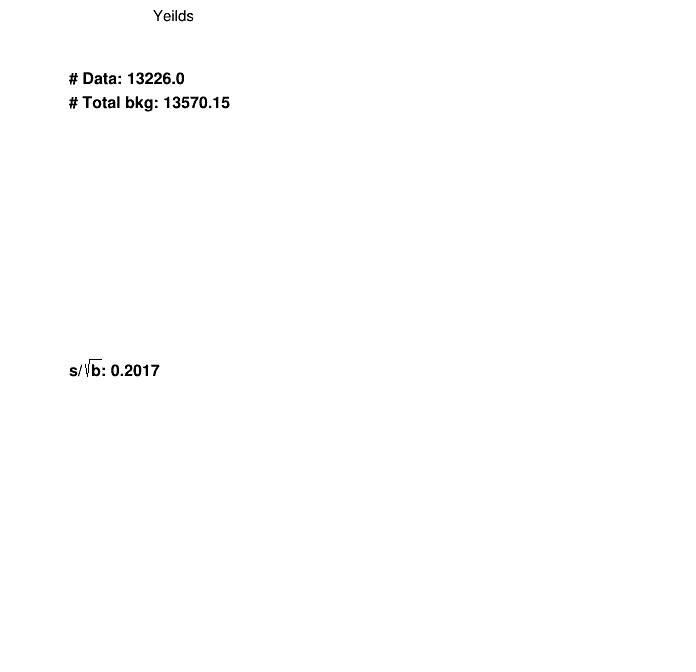

In [21]:
if DRAW_SR:
    region = "SR"

    with Pool() as p:
        p.starmap(wrapper_mp, list_variables) 
#     wrapper_mp('mass_pre', [45, 100, 1000, 'M_{ll} [GeV]'])

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)

# MET side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 539
DY1500To2000 : 642
DY2000To3000 : 620
DY500To700 : 570
DY700To800 : 479
DY800To1000 : 545
Zp-1700_CH-345 : 1464
Zp-1700_CH-595 : 1181
Zp-1700_CH-845 : 942
Zp-2100_CH-345 : 1372
Zp-2100_CH-595 : 1153
Zp-2100_CH-845 : 895
Zp-2500_CH-345 : 1300
Zp-2500_CH-595 : 1013
Zp-2500_CH-845 : 886
Zp-2900_CH-1095 : 645
Zp-2900_CH-1345 : 510
Zp-2900_CH-345 : 1241
Zp-2900_CH-595 : 1032
Zp-2900_CH-845 : 790
Zp-3300_CH-1095 : 620
Zp-3300_CH-1345 : 496
Zp-3300_CH-1595 : 438
Zp-3300_CH-345 : 1133
Zp-3300_CH-595 : 879
Zp-3700_CH-1095 : 525
Zp-3700_CH-1345 : 449
Zp-3700_CH-1595 : 391
Zp-3700_CH-1845 : 353
Zp-3700_CH-345 : 1020
Zp-3700_CH-595 : 865
Zp-3700_CH-845 : 675
Zp-4100_CH-1095 : 504
Zp-4100_CH-1345 : 421
Zp-4100_CH-1595 : 373
Zp-4100_CH-1845 : 299
Zp-4100_CH-345 : 901
Zp-4100_CH-595 : 752
Zp-4100_CH-845 : 621
TT : 202923
TTSe

       5.58784193e-02, 4.71464041e-02])}
here {'puweightUp': array([8.52118639e+01, 1.49836627e+01, 7.02264746e+02, 1.69934280e+02,
       2.35748379e+01, 0.00000000e+00, 1.14586490e-02, 3.09228318e+00,
       6.37096976e-01, 6.97478672e-01, 2.26327688e+00, 5.16385494e-02,
       9.47965608e-03, 6.10930201e-03, 8.94945949e-03, 5.91037262e-02,
       0.00000000e+00, 4.71898526e-03, 1.54158194e-02, 1.29539671e-04,
       8.84534970e-03, 2.41682864e-03, 1.76249374e-03, 6.95241340e-05,
       6.10054661e-04, 2.89944128e-05, 7.94443229e-05, 2.06938306e-08,
       2.28535475e-04, 1.01493476e-05]), 'puweightDown': array([3.56793583e+01, 4.51062018e+01, 4.23716321e+02, 9.64874085e+01,
       3.82877590e+01, 2.45770782e+00, 1.79199203e+00, 2.56092889e+00,
       8.35515926e-01, 1.09181760e+00, 2.27320760e+00, 8.72618608e-02,
       4.87872077e-02, 3.77691999e-02, 1.07069754e-02, 5.17020750e-02,
       2.32676766e-03, 9.74009099e-03, 2.09460379e-02, 0.00000000e+00,
       4.37165085e-03, 1.07555

       2.10652914e-02, 1.28473383e-02, 4.03087686e-01])}
here {'puweightUp': array([5.11075128e+02, 7.29821057e+02, 6.58642809e+01, 1.17621288e-01,
       9.72772937e+00, 5.39623692e+01, 1.21443721e+01, 8.78479195e+00,
       1.46047618e+01, 7.74822839e+00, 7.17526818e-01, 3.86652370e+00,
       2.83996974e-01, 2.21936790e+00, 1.30522279e-01, 1.43532008e-04,
       3.47608107e-01, 3.92249839e-02, 6.34621386e-02, 2.39643114e-02,
       5.96788373e-01, 1.07285520e-03, 1.47439099e-01, 1.94347615e-01,
       6.69731341e-02, 1.56163210e-03, 1.94813098e-02, 8.97154173e-04,
       4.17203508e-05, 3.90804214e-04, 1.06489525e-04]), 'puweightDown': array([5.70109133e+02, 4.47893733e+02, 2.37198725e+01, 2.19440610e+01,
       2.01621084e+01, 2.74135472e+01, 1.13661391e+01, 7.29635142e+00,
       4.90031474e+00, 9.40694117e+00, 1.20879343e+00, 5.05491981e+00,
       4.48131632e-01, 2.83557922e+00, 1.66564013e-01, 8.90767737e-03,
       4.44678256e-01, 1.17482216e-01, 1.68476095e-01, 1.99941320e-02

        0.        , 85.19584722, 76.36897113, 57.26167735, 78.16254385])}
here {'puweightUp': array([  0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
       535.53551588, 110.93239241, 138.40986528, 161.06827939]), 'puweightDown': array([  0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
       469.2127241 , 132.53509394,  50.33728736, 184.03308529]), 'l1prefiringUp': array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.02171206, 0.02005

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/METSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_lead_pre.pdf has

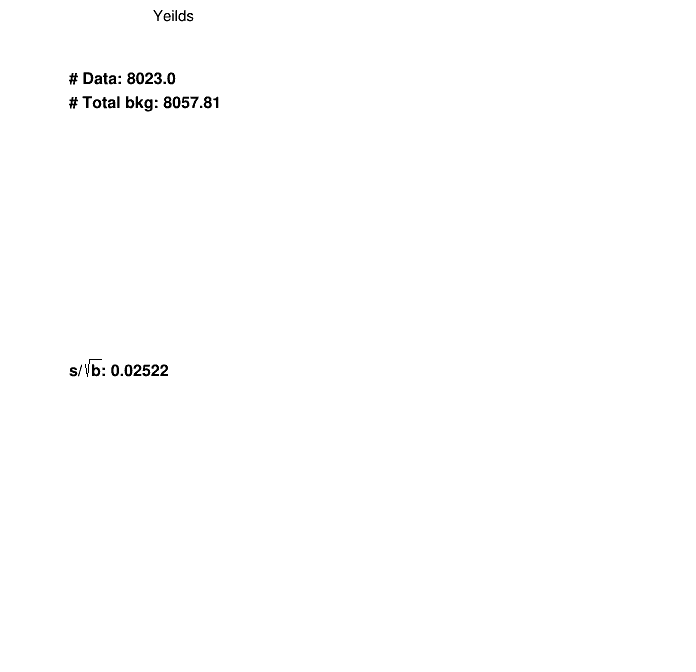

In [22]:
if RUN_SIDEBAND_MET:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "METSB"
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [23]:
if DUMP_SIDEBAND_MET_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_METSB.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# Mass side band

In [24]:
if RUN_SIDEBAND_MASS and not "em" in ERA:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    
    dic_variable={
        "PuppiMET_pre": [28, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
        "mass_pre": [1,80, 100, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    }

    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "MASSSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "mass_pre", "weight", 1, 80,  100, "M_{ll} [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.get_yeilds()
    hist.create_root_file(file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"] 
    for s in sys_list:
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Up', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Down', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist=HistStack(dic_df_met_u_tmp, "mass_pre", 'weightmetUp', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist=HistStack(dic_df_met_d_tmp, "mass_pre", 'weightmetDown', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")      

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 1
DY1500To2000 : 0
DY2000To3000 : 1
DY500To700 : 0
DY700To800 : 0
DY800To1000 : 0
Zp-1700_CH-345 : 15
Zp-1700_CH-595 : 382
Zp-1700_CH-845 : 1143
Zp-2100_CH-345 : 14
Zp-2100_CH-595 : 195
Zp-2100_CH-845 : 662
Zp-2500_CH-345 : 6
Zp-2500_CH-595 : 98
Zp-2500_CH-845 : 323
Zp-2900_CH-1095 : 395
Zp-2900_CH-1345 : 520
Zp-2900_CH-345 : 4
Zp-2900_CH-595 : 46
Zp-2900_CH-845 : 197
Zp-3300_CH-1095 : 263
Zp-3300_CH-1345 : 372
Zp-3300_CH-1595 : 433
Zp-3300_CH-345 : 5
Zp-3300_CH-595 : 22
Zp-3700_CH-1095 : 189
Zp-3700_CH-1345 : 275
Zp-3700_CH-1595 : 334
Zp-3700_CH-1845 : 364
Zp-3700_CH-345 : 6
Zp-3700_CH-595 : 17
Zp-3700_CH-845 : 91
Zp-4100_CH-1095 : 118
Zp-4100_CH-1345 : 188
Zp-4100_CH-1595 : 222
Zp-4100_CH-1845 : 229
Zp-4100_CH-345 : 5
Zp-4100_CH-595 : 10
Zp-4100_CH-845 : 41
TT : 88358
TTSemi : 198
TTZ : 71885
DY : 1680
top : 97
a

       4.52658589e-02, 3.15454946e-01, 8.52358487e-02])}
here {'puweightUp': array([6.69218172e+02, 2.21347095e+02, 1.64784051e+02, 3.89807868e+01,
       1.40623612e+01, 9.13345385e+00, 4.58001343e+00, 3.08661081e+01,
       2.46658562e+00, 1.04833206e+01, 1.20878069e-02, 1.26181741e+00,
       9.41289065e-01, 1.10328319e+01, 1.60117225e-01, 8.59186320e-02,
       0.00000000e+00, 1.38721311e-02, 4.67983069e-02, 5.43076117e+00,
       2.01953471e-03, 2.48496106e+00, 1.38761025e-02, 3.63879802e-01,
       5.99279050e-02, 3.98037864e-02, 9.73596810e-03, 1.64036932e-02,
       9.17291409e-04, 2.63626691e-02, 6.83163576e-02]), 'puweightDown': array([5.48043295e+02, 6.38479998e+01, 1.46088200e+02, 5.36318478e+01,
       6.09026399e+01, 1.73487646e+01, 1.51027362e+01, 4.48643368e+01,
       6.47477366e-01, 3.88338904e+01, 4.89502076e+00, 0.00000000e+00,
       5.68411624e-01, 9.44788395e+00, 7.92713405e-02, 0.00000000e+00,
       1.28969749e-01, 1.36859253e-05, 3.21040695e-01, 1.04169339e+01

       8.83004341e-02, 8.68283319e-02, 1.68646740e-02, 1.96934154e-01])}
here {'puweightUp': array([1.92690142e+02, 2.46167322e+02, 1.48373723e+01, 8.35638427e-01,
       5.64225291e+00, 0.00000000e+00, 3.40446567e-01, 1.02399797e+00,
       2.10029221e-01, 1.79938651e+00, 5.15986669e-01, 3.23809770e-01,
       6.16012728e-01, 7.37069966e-03, 3.88454031e-03, 1.23227649e-02,
       5.63801329e-04, 0.00000000e+00, 4.11430106e-03, 8.77572180e-03,
       2.56890685e-03, 4.78622483e-03, 2.41816344e-03, 1.94587902e-04,
       3.76139419e-04, 5.79470491e-05, 1.60570481e-06, 1.49406386e-03]), 'puweightDown': array([3.00184324e+02, 2.10415882e+02, 1.71150126e+01, 3.26264594e-01,
       1.75088124e+00, 2.29123264e-01, 6.71147476e-01, 9.41946841e-01,
       2.91902202e-01, 3.10105049e+00, 5.27107015e-01, 2.24462125e-01,
       4.25063865e-01, 1.07191976e-03, 9.56577460e-03, 3.28105685e-02,
       4.92674808e-03, 4.04873088e-03, 3.50044221e-03, 1.82808130e-02,
       2.58797817e-04, 1.90735356e-03

       0.00000000e+00, 6.74014304e-03])}
here {'puweightUp': array([1.15786632e+03, 5.95727610e+02, 3.02834823e+01, 1.12009215e+01,
       2.57946949e+01, 0.00000000e+00, 1.82587668e+01, 1.67581659e+00,
       9.97830833e+00, 4.60292698e+00, 9.53300325e-01, 2.24516213e+00,
       2.76465051e-01, 5.10597320e-01, 6.55908150e-02, 6.61943752e-02,
       3.20158117e-04, 4.32558451e-05, 9.25064201e-06, 4.34913783e-07,
       7.16599008e-06, 1.12507014e-05, 3.70419128e-05, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 6.17693000e-06,
       0.00000000e+00, 3.37117826e-05]), 'puweightDown': array([7.88849959e+02, 3.02114762e+02, 2.48193442e+02, 4.67455512e+01,
       1.49827675e+01, 5.40816637e-01, 3.55792948e+01, 3.26698461e+00,
       8.55618443e+00, 3.27205102e+00, 6.29880810e-01, 1.67421393e+00,
       7.99747724e-01, 9.71397802e-01, 6.56532737e-02, 5.77057200e-02,
       3.05117786e-04, 3.26581822e-05, 8.28188942e-06, 1.45118995e-06,
       8.61824473e-06, 1.08969

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/MASSSB/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/MASSSB/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/MASSSB/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/MASSSB/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_pre.pdf has been create

In [25]:
if DUMP_SIDEBAND_MASS_PKL and not "em" in ERA:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_MASS.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# PT side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 55
DY1500To2000 : 55
DY2000To3000 : 40
DY500To700 : 66
DY700To800 : 72
DY800To1000 : 70
Zp-1700_CH-345 : 1385
Zp-1700_CH-595 : 1130
Zp-1700_CH-845 : 899
Zp-2100_CH-345 : 1262
Zp-2100_CH-595 : 1119
Zp-2100_CH-845 : 878
Zp-2500_CH-345 : 1161
Zp-2500_CH-595 : 1105
Zp-2500_CH-845 : 919
Zp-2900_CH-1095 : 685
Zp-2900_CH-1345 : 583
Zp-2900_CH-345 : 1079
Zp-2900_CH-595 : 1061
Zp-2900_CH-845 : 876
Zp-3300_CH-1095 : 679
Zp-3300_CH-1345 : 625
Zp-3300_CH-1595 : 449
Zp-3300_CH-345 : 987
Zp-3300_CH-595 : 975
Zp-3700_CH-1095 : 595
Zp-3700_CH-1345 : 544
Zp-3700_CH-1595 : 444
Zp-3700_CH-1845 : 379
Zp-3700_CH-345 : 951
Zp-3700_CH-595 : 924
Zp-3700_CH-845 : 806
Zp-4100_CH-1095 : 617
Zp-4100_CH-1345 : 515
Zp-4100_CH-1595 : 424
Zp-4100_CH-1845 : 380
Zp-4100_CH-345 : 880
Zp-4100_CH-595 : 865
Zp-4100_CH-845 : 726
TT : 124098
TTSemi : 230

{'puweightUp': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'puweightDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'l1prefiringUp': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'l1prefiringDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'effSFUp': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'effSFDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'topSFUp': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'topSFDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'trigSFUp': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'trigSFDown': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'sum_up': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]), 'sum_down': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])}
here {'puweightUp': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'puweightD

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/PTSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/PTSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/PTSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/PTSB/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100_pt_lead_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230419_18/Presel/ee18/PTSB/norm_m

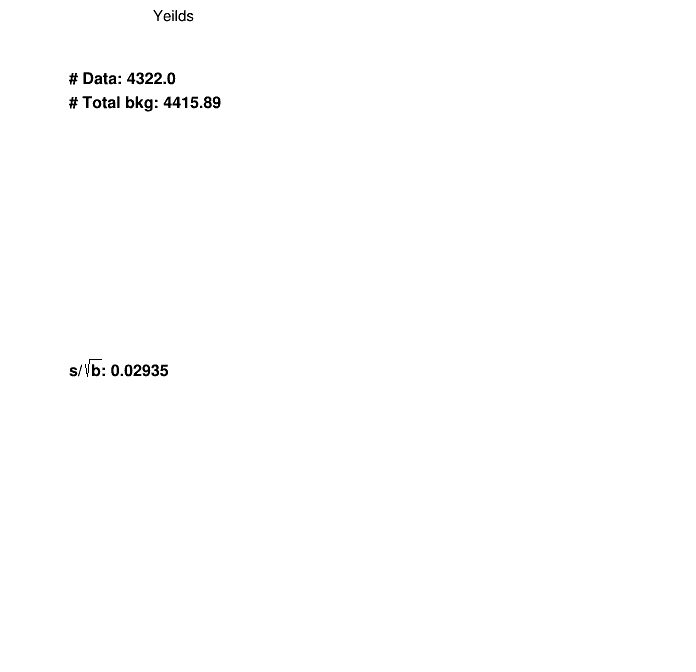

In [26]:
if RUN_SIDEBAND_PT:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [14, 0, 660, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
        "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
        "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
        "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
        "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
        "U_pre": [14, 0, 660, "U [GeV]"],
        "JZB_pre": [14, 80, 660, "JZB"],
        "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
        "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
        "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
        "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "PTSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [27]:
if DUMP_SIDEBAND_PT_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_PT.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# b tag selection

In [28]:
if RUN_BTAG:
    dic_variable={
        "MET_pre": [25, 0, 500, "p_{T}^{miss} [GeV]"],    
#         "PuppiMET_pre": [50, 0, 500, "Puppi p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#         "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"], 
        "nbjetflav_pre": [10, 0, 10, "N bjetflav"], 
#         "nbjet_pre": [10, 0, 10, "N bjet"], 
        "njet_pre": [10, 0, 10, "N jet"], 
#         "njet_l_pre": [9, 1, 10, "N  l jet"],     
#         "njet_c_pre": [9, 1, 10, "N  c jet"],     
#         "njet_b_pre": [9, 1, 10, "N  b jet"],    
#         "btagSF0_pre": [40, 0.9, 1.3, "B SF"],    
    }
    
#     base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>80 and PuppiMET_pre>150 and MT_pre>130"
    base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    dic_df_raw={}
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and njet_pre==1" #temp!
#     query_str=base_line+" and nbjetflav_pre==0" #temp!
    query_str=base_line #temp!

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)  
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d
        
    sys_list = ["weight", "wobsf", "wotop"]
    for sys_key in sys_list:
        for variable, r in dic_variable.items():
            os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/Beq0/"+sys_key)
            hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
            c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/preselv1_"+query_str) 
    
#     hist=HistStack(dic_df_raw, "btagSF0_pre", "genweight_pre", 40, 0.9, 1.3, "B SF")            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/NONBTAG/"+sys_key+"/genweight_pre_preselv1_"+query_str, is_dnn=False) 

        #simply from last instance
        print(hist.get_yeilds())
        hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/pie_"+query_str)
        print(hist.nbin)    
    
#     with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_Beq0.pkl", "wb") as f:
#         pickle.dump(nested_dic_df, f)

# Export variables

In [29]:
if EXPORT_VARIABLE:
    # draw
    # get plot configuration
    dic_variable={
    #     "pt_trail_pre": [8, 40, 300, "p_{T}(l_{trail}) [GeV]"],
    #     "MT2_pre": [8, 0, 160, "M_{T2} [GeV]"],
        "H3PP_pre": [19, 95, 900, "H3PP [GeV]"],     
    }
    sys_src={
        "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre"]
    #     "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre", "topSF_pre"]
    }
    # sys_src=[]
    for key in dic_df_raw:
        if "Zp" in key:
            for variable, r in dic_variable.items():
                hist=HistStack(dic_df_raw, variable, sys_src, "presel", r[0], r[1], r[2], r[3])            
                c1=hist.draw_hist(key, ERA, ERA+"_exportdev"+query_str, True) 
                hist.create_root_file(key, variable, channel)
                hist.export_hist(key, variable, channel, "") 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie()
    print(hist.nbin)


# Signal Acc x Eff x presel

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file sigeff_ee18.pdf has been created


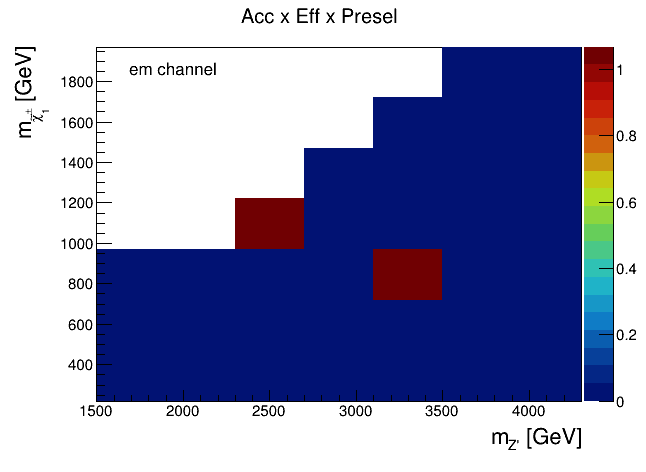

In [30]:
Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# missing bin by hand
h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+"em channel}}")

c1.Draw()
c1.SaveAs("sigeff_"+ERA+".pdf")